In [1]:
import tensorflow as tf
import numpy as np

# numpy 의 값들을 출력할 때 소수점 3자리까지 출력
np.set_printoptions(precision=3)

In [2]:
a = np.array([1, 2, 3], dtype=np.int32)
b = [4, 5, 6]

In [3]:
t_a = tf.convert_to_tensor(a)
t_b = tf.convert_to_tensor(b)

In [4]:
print("type a", type(a))
print("type b", type(b))

type a <class 'numpy.ndarray'>
type b <class 'list'>


In [5]:
print("t_a=", t_a)
print("t_b=", t_b)

# shape=(3,) 속성과 원본 데이터 타입 int32이 함께 출력

t_a= tf.Tensor([1 2 3], shape=(3,), dtype=int32)
t_b= tf.Tensor([4 5 6], shape=(3,), dtype=int32)


In [6]:
t_ones = tf.ones((2, 3)) # 2차원 배열 2x3 에 1을 채워 생성
t_ones.shape

TensorShape([2, 3])

In [7]:
# 텐서가 참조하는 값을 얻으려면 .numpy() 메소드를 호출해야한다
t_ones.numpy()

array([[1., 1., 1.],
       [1., 1., 1.]], dtype=float32)

In [8]:
t_ones.numpy()[0][1]

1.0

In [9]:
# 상수 값을 가지는 텐서 만들기
const_tensor = tf.constant([1.2, 5, np.pi], dtype=tf.float32)

In [10]:
print(const_tensor)

tf.Tensor([1.2   5.    3.142], shape=(3,), dtype=float32)


In [11]:
# 텐서의 데이터 타입을 바꾸기
print(t_a.dtype)

t_a_new = tf.cast(t_a, tf.int64)
print(t_a_new.dtype)

<dtype: 'int32'>
<dtype: 'int64'>


In [12]:
# 텐서의 전치(transpose)
t = tf.random.uniform(shape=(3, 5))
t_tr = tf.transpose(t)
print(t.shape, '=>', t_tr.shape)

(3, 5) => (5, 3)


In [13]:
# 텐서의 크기 바꾸기(ex: 1D 벡터에서 2D 배열로)
t = tf.zeros((30,))
t_reshape = tf.reshape(t, shape=(5,6)) # 원소의 개수가 동일하게
print(t_reshape.shape)

(5, 6)


In [14]:
# 불필요한 차원 삭제하기(크기가 1인 차원)
t = tf.zeros((1, 2, 1, 4, 1)) # rank=5 텐서
t_sqz = tf.squeeze(t, axis=(2, 4)) # 2번째와 4번째 크기 1인 차원 삭제
print(t.shape, '=>', t_sqz.shape)

(1, 2, 1, 4, 1) => (1, 2, 4)


In [15]:
t_sqz = tf.squeeze(t) # 모든 크기가 1인 차원 삭제
print(t.shape, '=>', t_sqz.shape)

(1, 2, 1, 4, 1) => (2, 4)


In [16]:
t1 = tf.convert_to_tensor(np.array([[1, 2], [3,4]]))
t2 = tf.convert_to_tensor(np.array([[5, 6], [7,8]]))

In [17]:
t1

<tf.Tensor: shape=(2, 2), dtype=int64, numpy=
array([[1, 2],
       [3, 4]])>

In [18]:
t2

<tf.Tensor: shape=(2, 2), dtype=int64, numpy=
array([[5, 6],
       [7, 8]])>

In [19]:
t3 = tf.multiply(t1, t2) # 원소별 곱셈

In [20]:
t3.numpy()

array([[ 5, 12],
       [21, 32]])

In [21]:
t4 = tf.math.reduce_mean(t3, axis=0)
# 각 axis=0(열) 의 평균을 구합니다.  - 행의 방향으로 계산
# axis=1이면 각 행의 평균을 구합니다. - 열의 방향으로 계산

In [22]:
t4.numpy()

array([13, 22])

In [23]:
t5 = tf.linalg.matmul(t1, t2) # 행렬곱

In [24]:
t5.numpy()

array([[19, 22],
       [43, 50]])

In [25]:
#tf.norm 연산은 float 타입만 지원
t1 = tf.cast(t1, dtype=tf.float32)

# ord: L1 norm 인지 L2 norm 인지를 결정
# axis: 0-각 열에 대한 norm, 1-각 행에 대한 norm
l1_norm_t1 = tf.norm(t1, ord=1, axis=1).numpy()
l2_norm_t1 = tf.norm(t1, ord=2, axis=1).numpy()

In [26]:
print(t1.numpy())
print(l1_norm_t1)
print(l2_norm_t1)

[[1. 2.]
 [3. 4.]]
[3. 7.]
[2.236 5.   ]


In [27]:
tf.random.set_seed(1) # 랜덤 값 생성을 위한 seed 값 지정
t = tf.random.uniform((6, )) # 크기 6인 텐서로 균일 분포 난수 생성

print(t.numpy())

[0.165 0.901 0.631 0.435 0.292 0.643]


In [28]:
# 크기 6인 텐서를 3개로 분할 = 크기 2 x 3개
t_splits = tf.split(t, num_or_size_splits=3)

print(type(t_splits))

for item in t_splits:
    print(item.numpy())

<class 'list'>
[0.165 0.901]
[0.631 0.435]
[0.292 0.643]


In [29]:
tf.random.set_seed(1)
t = tf.random.uniform((5,)) # 크기 5인 텐서로 균일 분포 난수 생성

print(t.numpy())

[0.165 0.901 0.631 0.435 0.292]


In [30]:
# 크기 5인 텐서가 크기가 각각 3, 2 의 텐서로 나누어짐
t_splits = tf.split(t, num_or_size_splits=[3, 2])

print(type(t_splits))

for item in t_splits:
    print(item.numpy())

<class 'list'>
[0.165 0.901 0.631]
[0.435 0.292]


In [31]:
A = tf.ones((3,))
B = tf.zeros((3,))

S1 = tf.stack([A, B], axis=1) # 각 텐서가 열의 방향으로 쌓임
S2 = tf.stack([A, B], axis=0) # 각 텐서가 행의 방향으로 쌓임

print(S1.numpy())
print(S2.numpy())

[[1. 0.]
 [1. 0.]
 [1. 0.]]
[[1. 1. 1.]
 [0. 0. 0.]]


In [32]:
A = tf.ones((3,))
B = tf.zeros((2,))

C = tf.concat([A, B], axis=0)

print(C.numpy())

[1. 1. 1. 0. 0.]


In [33]:
a = [1.2, 3.4, 7.5, 4.1, 5.0, 1.0]
ds = tf.data.Dataset.from_tensor_slices(a)

print(ds)

<_TensorSliceDataset element_spec=TensorSpec(shape=(), dtype=tf.float32, name=None)>


In [34]:
for item in ds:
    print(item)

tf.Tensor(1.2, shape=(), dtype=float32)
tf.Tensor(3.4, shape=(), dtype=float32)
tf.Tensor(7.5, shape=(), dtype=float32)
tf.Tensor(4.1, shape=(), dtype=float32)
tf.Tensor(5.0, shape=(), dtype=float32)
tf.Tensor(1.0, shape=(), dtype=float32)


In [35]:
ds_batch = ds.batch(batch_size=3)
for i, elem in enumerate(ds_batch, 1):
    print('batch {}:{}'.format(i, elem.numpy()))

batch 1:[1.2 3.4 7.5]
batch 2:[4.1 5.  1. ]


In [36]:
ds_batch = ds.batch(batch_size=4)
for i, elem in enumerate(ds_batch, 1):
    print('batch {}:{}'.format(i, elem.numpy()))

batch 1:[1.2 3.4 7.5 4.1]
batch 2:[5. 1.]


In [37]:
ds_batch = ds.batch(batch_size=4, drop_remainder=True)
for i, elem in enumerate(ds_batch, 1):
    print('batch {}:{}'.format(i, elem.numpy()))

batch 1:[1.2 3.4 7.5 4.1]


In [38]:
tf.random.set_seed(1)

# t_x 의 특징벡터는 길이가 3이고 총 4개의 데이터
t_x = tf.random.uniform([4, 3], dtype=tf.float32)
t_y = tf.range(4)

ds_x = tf.data.Dataset.from_tensor_slices(t_x)
ds_y = tf.data.Dataset.from_tensor_slices(t_y)

ds_joint = tf.data.Dataset.zip((ds_x, ds_y))

for example in ds_joint:
    print('  x: ', example[0].numpy(),
          '  y: ', example[1].numpy())

  x:  [0.165 0.901 0.631]   y:  0
  x:  [0.435 0.292 0.643]   y:  1
  x:  [0.976 0.435 0.66 ]   y:  2
  x:  [0.605 0.637 0.614]   y:  3


In [39]:
ds_joint = tf.data.Dataset.from_tensor_slices((t_x, t_y))

for example in ds_joint:
    print('  x: ', example[0].numpy(),
          '  y: ', example[1].numpy())

  x:  [0.165 0.901 0.631]   y:  0
  x:  [0.435 0.292 0.643]   y:  1
  x:  [0.976 0.435 0.66 ]   y:  2
  x:  [0.605 0.637 0.614]   y:  3


In [40]:
ds_trans = ds_joint.map(lambda x, y: (x*2-1.0, y))

for example in ds_trans:
    print('  x: ', example[0].numpy(),
          '  y: ', example[1].numpy())

  x:  [-0.67   0.803  0.262]   y:  0
  x:  [-0.131 -0.416  0.285]   y:  1
  x:  [ 0.952 -0.13   0.32 ]   y:  2
  x:  [0.21  0.273 0.229]   y:  3


In [41]:
tf.random.set_seed(1)
ds = ds_joint.shuffle(buffer_size=len(t_x))

for example in ds:
    print('  x: ', example[0].numpy(),
          '  y: ', example[1].numpy())

  x:  [0.976 0.435 0.66 ]   y:  2
  x:  [0.435 0.292 0.643]   y:  1
  x:  [0.165 0.901 0.631]   y:  0
  x:  [0.605 0.637 0.614]   y:  3


In [42]:
ds = ds_joint.batch(batch_size=3, drop_remainder=False)

for i,(batch_x, batch_y) in enumerate(ds):
    print(i)
    print('배치 x:\n', batch_x.numpy())
    print('배치 y:\n', batch_y.numpy())

0
배치 x:
 [[0.165 0.901 0.631]
 [0.435 0.292 0.643]
 [0.976 0.435 0.66 ]]
배치 y:
 [0 1 2]
1
배치 x:
 [[0.605 0.637 0.614]]
배치 y:
 [3]


In [43]:
ds = ds_joint.batch(3).repeat(count=2) # 배치 데이터셋을 두번 반복

for i,(batch_x, batch_y) in enumerate(ds):
    print(i, batch_x.shape, batch_y.numpy())

0 (3, 3) [0 1 2]
1 (1, 3) [3]
2 (3, 3) [0 1 2]
3 (1, 3) [3]


In [44]:
ds = ds_joint.repeat(count=2).batch(3) # 전체 데이터셋을 두번 반복한 것을 배치로

for i,(batch_x, batch_y) in enumerate(ds):
    print(i, batch_x.shape, batch_y.numpy())

0 (3, 3) [0 1 2]
1 (3, 3) [3 0 1]
2 (2, 3) [2 3]


In [45]:
tf.random.set_seed(1)

## 순서 1: shuffle -> batch -> repeat
ds = ds_joint.shuffle(4).batch(2).repeat(3)

for i,(batch_x, batch_y) in enumerate(ds):
    print(i, batch_x.shape, batch_y.numpy())

0 (2, 3) [2 1]
1 (2, 3) [0 3]
2 (2, 3) [0 3]
3 (2, 3) [1 2]
4 (2, 3) [3 0]
5 (2, 3) [1 2]


In [46]:
tf.random.set_seed(1)

## 순서 2: batch -> shuffle -> repeat
ds = ds_joint.batch(2).shuffle(4).repeat(3)

for i,(batch_x, batch_y) in enumerate(ds):
    print(i, batch_x.shape, batch_y.numpy())

0 (2, 3) [0 1]
1 (2, 3) [2 3]
2 (2, 3) [0 1]
3 (2, 3) [2 3]
4 (2, 3) [2 3]
5 (2, 3) [0 1]


In [47]:
#pathlib 을 이용한 파일의 리스트 만들기
import pathlib

imgdir_path = pathlib.Path('cat_dog_images')
file_list = sorted([str(path) for path in imgdir_path.glob('*.jpg')])

print(file_list)

['cat_dog_images/cat-01.jpg', 'cat_dog_images/cat-02.jpg', 'cat_dog_images/cat-03.jpg', 'cat_dog_images/dog-01.jpg', 'cat_dog_images/dog-02.jpg', 'cat_dog_images/dog-03.jpg']


이미지 크기:  (900, 1200, 3)
이미지 크기:  (900, 1200, 3)
이미지 크기:  (900, 742, 3)
이미지 크기:  (800, 1200, 3)
이미지 크기:  (800, 1200, 3)
이미지 크기:  (900, 1200, 3)


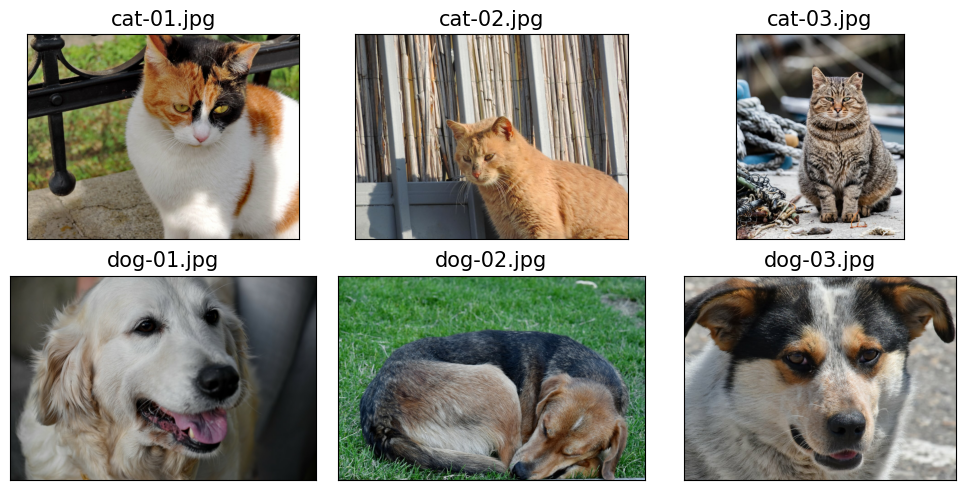

In [48]:
# 이미지 샘플 출력
import matplotlib.pyplot as plt
import os

fig = plt.figure(figsize=(10, 5))
for i,file in enumerate(file_list):
    img_raw = tf.io.read_file(file)
    img = tf.image.decode_image(img_raw)
    print('이미지 크기: ', img.shape)
    ax = fig.add_subplot(2, 3, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(img)
    ax.set_title(os.path.basename(file), size=15)

plt.tight_layout()
plt.show()

In [49]:
# 파일명으로 cat:0, dog:1 로 레이블링
labels = [1 if 'dog' in os.path.basename(file) else 0 for file in file_list]
print(labels)

[0, 0, 0, 1, 1, 1]


In [50]:
# 파일명 x, 레이블 y 로 데이터셋 생성
ds_files_labels = tf.data.Dataset.from_tensor_slices((file_list, labels))

for item in ds_files_labels:
    print(item[0].numpy(), item[1].numpy())

b'cat_dog_images/cat-01.jpg' 0
b'cat_dog_images/cat-02.jpg' 0
b'cat_dog_images/cat-03.jpg' 0
b'cat_dog_images/dog-01.jpg' 1
b'cat_dog_images/dog-02.jpg' 1
b'cat_dog_images/dog-03.jpg' 1


In [51]:
# 이미지를 로드하고 원본 데이터를 디코딩 → 동일한 크기(120x80)로 변경 → 데이터 정규화
def load_and_preprocess(path, label):
    img_width, img_height = 120, 80
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [img_height, img_width])
    image /= 255.0

    return image, label


# map 메서드에 전처리기를 호출하여 이미지-레이블 데이터셋으로 만든다
ds_images_labels = ds_files_labels.map(load_and_preprocess)

(80, 120, 3) 0
(80, 120, 3) 0
(80, 120, 3) 0
(80, 120, 3) 1
(80, 120, 3) 1
(80, 120, 3) 1


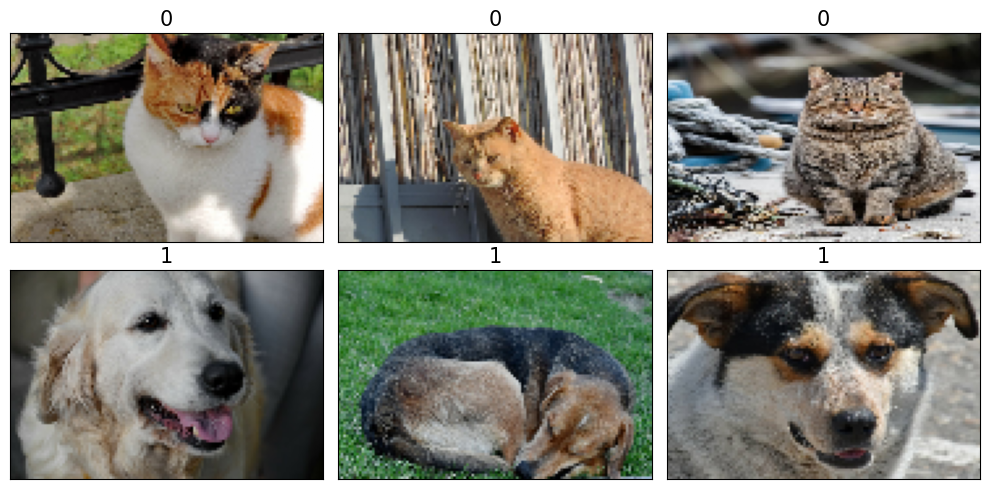

In [52]:
# 데이터셋 출력
fig = plt.figure(figsize=(10, 5))
for i,example in enumerate(ds_images_labels):
    print(example[0].shape, example[1].numpy())
    ax = fig.add_subplot(2, 3, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(example[0])
    ax.set_title('{}'.format(example[1].numpy()),
                 size=15)

plt.tight_layout()
plt.show()

In [53]:
import tensorflow_datasets as tfds

# 사용가능한 데이터셋 목록 확인
print(len(tfds.list_builders()))
print(tfds.list_builders()[:5])

W0000 00:00:1793462043.251336 150228780 google_auth_provider.cc:196] All attempts to get a Google authentication bearer token failed, returning an empty token. Retrieving token from files failed with "NOT_FOUND: Could not locate the credentials file.". Retrieving token from GCE failed with "FAILED_PRECONDITION: Error executing an HTTP request: libcurl code 6 meaning 'Could not resolve hostname', error details: Could not resolve host: metadata.google.internal".


1321
['abstract_reasoning', 'accentdb', 'aeslc', 'aflw2k3d', 'ag_news_subset']


In [54]:
# tfds.builder 를 이용한 데이터셋 정보 확인 및 데이터셋 다운로드
mnist_bldr = tfds.builder('mnist')

# 데이터 셋을 구성하고 있는 특징
print(mnist_bldr.info.features)
print('\n', 30*"=", '\n')

# 데이터 셋을 구성하고 있는 특징을 접근하기 위한 dictionary key 확인
print(mnist_bldr.info.features.keys())
print('\n', 30*"=", '\n')

# 이미지 특징에 대한 정보
print(mnist_bldr.info.features['image'])
print('\n', 30*"=", '\n')

# citation 정보
print(mnist_bldr.info.citation)

FeaturesDict({
    'image': Image(shape=(28, 28, 1), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
})


dict_keys(['image', 'label'])


Image(shape=(28, 28, 1), dtype=uint8)


@article{lecun2010mnist,
  title={MNIST handwritten digit database},
  author={LeCun, Yann and Cortes, Corinna and Burges, CJ},
  journal={ATT Labs [Online]. Available: http://yann.lecun.com/exdb/mnist},
  volume={2},
  year={2010}
}


In [55]:
mnist_bldr.download_and_prepare()

In [56]:
datasets = mnist_bldr.as_dataset(shuffle_files=False)

datasets.keys()

dict_keys(['train', 'test'])

In [57]:
ds_train = datasets['train']

example = next(iter(ds_train))
print(type(example))
print(example.keys())

<class 'dict'>
dict_keys(['image', 'label'])


I0000 00:00:1793462047.641271 150228871 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
W0000 00:00:1793462047.645307 150228455 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


In [58]:
ds_train = ds_train.map(lambda item:(item['image'], item['label']))

In [59]:
ds_train = ds_train.batch(20)

image, labels = next(iter(ds_train))

print(image.shape, labels)

(20, 28, 28, 1) tf.Tensor([4 1 0 7 8 1 2 7 1 6 6 4 7 7 3 3 7 9 9 1], shape=(20,), dtype=int64)


W0000 00:00:1793462047.672004 150228949 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


In [60]:
# tfds.load 를 이용한 데이터셋 다운로드 및 데이터셋 정보 확인
mnist, mnist_info = tfds.load('mnist', with_info=True, shuffle_files=False)

print(mnist_info)
print(mnist.keys())

tfds.core.DatasetInfo(
    name='mnist',
    full_name='mnist/3.0.1',
    description="""
    The MNIST database of handwritten digits.
    """,
    homepage='http://yann.lecun.com/exdb/mnist/',
    data_dir='/Users/kyungeun/tensorflow_datasets/mnist/3.0.1',
    file_format=tfrecord,
    download_size=11.06 MiB,
    dataset_size=21.00 MiB,
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=10000, num_shards=1>,
        'train': <SplitInfo num_examples=60000, num_shards=1>,
    },
    citation="""@article{lecun2010mnist,
      title={MNIST handwritten digit database},
      author={LeCun, Yann and Cortes, Corinna and Burges, CJ},
      journal={ATT Labs [Online]. Available: http://yann.lecun.com/exdb/mnist},
      volume={2},


In [61]:
ds_train = mnist['train']

ds_train = ds_train.map(lambda item:
     (item['image'], item['label']))

ds_train = ds_train.batch(10)

batch = next(iter(ds_train))

print(batch[0].shape, batch[1]) # batch[0] image, batch[1] label

(10, 28, 28, 1) tf.Tensor([4 1 0 7 8 1 2 7 1 6], shape=(10,), dtype=int64)


W0000 00:00:1793462047.724422 150229025 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


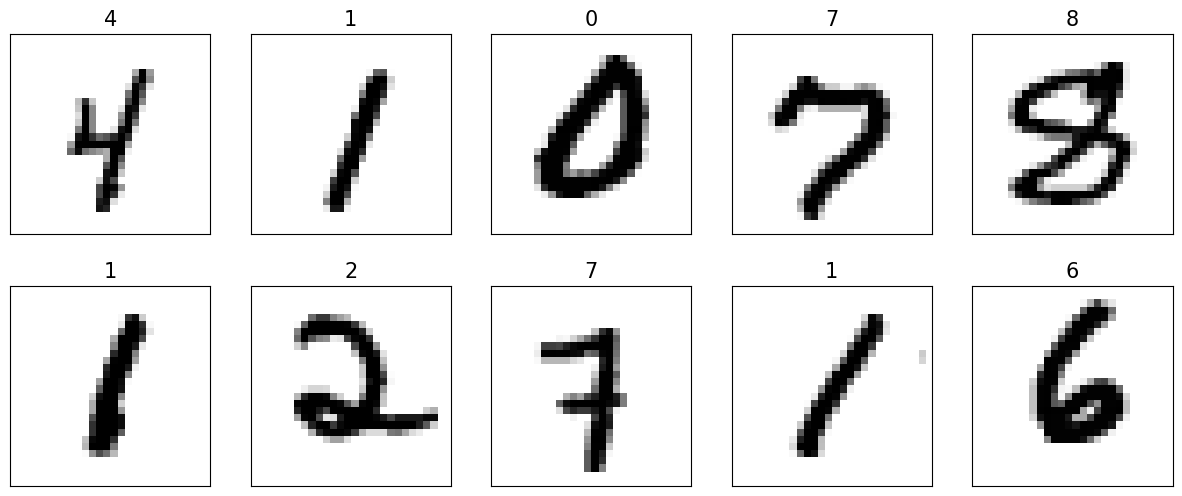

In [62]:
# week6_1.txt
fig = plt.figure(figsize=(15, 6))
for i,(image,label) in enumerate(zip(batch[0], batch[1])):
    ax = fig.add_subplot(2, 5, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(image[:, :, 0], cmap='gray_r')
    ax.set_title('{}'.format(label), size=15)

plt.show()

In [63]:
import tensorflow_datasets as tfds

iris, iris_info = tfds.load('iris', with_info=True)
print(iris_info)

tfds.core.DatasetInfo(
    name='iris',
    full_name='iris/2.1.0',
    description="""
    This is perhaps the best known database to be found in the pattern recognition
    literature. Fisher's paper is a classic in the field and is referenced
    frequently to this day. (See Duda & Hart, for example.) The data set contains
    3 classes of 50 instances each, where each class refers to a type of iris
    plant. One class is linearly separable from the other 2; the latter are NOT
    linearly separable from each other.
    """,
    homepage='https://archive.ics.uci.edu/ml/datasets/iris',
    data_dir='/Users/kyungeun/tensorflow_datasets/iris/2.1.0',
    file_format=tfrecord,
    download_size=3.65 KiB,
    dataset_size=7.62 KiB,
    features=FeaturesDict({
        'features': Tensor(shape=(4,), dtype=float32),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=3),
    }),
    supervised_keys=('features', 'label'),
    disable_shuffling=False,
    nondeterministic_order=Fal

In [64]:
tf.random.set_seed(1)

ds_orig = iris['train']
ds_orig = ds_orig.shuffle(150, reshuffle_each_iteration=False)
#reshuffle_each_iteration: iteration 마다 shuffle 을 수행할지를 결정

print(next(iter(ds_orig)))

ds_train_orig = ds_orig.take(100) # 처음부터 100개 가져오기
ds_test = ds_orig.skip(100) # 처음부터 100개를 제외한 나머지 가져오기

{'features': <tf.Tensor: shape=(4,), dtype=float32, numpy=array([6.5, 3. , 5.2, 2. ], dtype=float32)>, 'label': <tf.Tensor: shape=(), dtype=int64, numpy=2>}


In [65]:
ds_train_orig = ds_train_orig.map(
    lambda x: (x['features'], x['label']))

ds_test = ds_test.map(
    lambda x: (x['features'], x['label']))

In [66]:
next(iter(ds_test))

(<tf.Tensor: shape=(4,), dtype=float32, numpy=array([5.7, 2.5, 5. , 2. ], dtype=float32)>,
 <tf.Tensor: shape=(), dtype=int64, numpy=2>)

In [67]:
iris_model = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='sigmoid',
                          name='fc1', input_shape=(4,)),
    tf.keras.layers.Dense(3, name='fc2', activation='softmax')])

iris_model.summary()

/opt/miniconda3/envs/mldl/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fc1 (Dense)                     │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131 (524.00 B)

 Trainable params: 131 (524.00 B)

 Non-trainable params: 0 (0.00 B)

In [68]:
iris_model.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

In [69]:
num_epochs = 100
training_size = 100
batch_size = 2
steps_per_epoch = int(np.ceil(training_size / batch_size))

ds_train = ds_train_orig.shuffle(buffer_size=training_size)
ds_train = ds_train.repeat()
ds_train = ds_train.batch(batch_size=batch_size)
ds_train = ds_train.prefetch(buffer_size=1000)


history = iris_model.fit(ds_train, epochs=num_epochs,
                         steps_per_epoch=steps_per_epoch,
                         verbose=1)

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 448us/step - accuracy: 0.2800 - loss: 1.8120 
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 368us/step - accuracy: 0.5200 - loss: 1.4803    
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 345us/step - accuracy: 0.6300 - loss: 1.2499
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 341us/step - accuracy: 0.6200 - loss: 1.0941
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 357us/step - accuracy: 0.5600 - loss: 0.9990
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 362us/step - accuracy: 0.6500 - loss: 0.9528
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 340us/step - accuracy: 0.7200 - loss: 0.9134
Epoch 8/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 367us/step - accuracy: 0.7200 - loss: 0.8890
Epoch 9/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 356us/step - accuracy: 0.7200 - loss: 0.8529
Epoch 10/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 356us/step - accuracy: 0.7200 - loss: 0.8221
Epoch 11/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 345us/step - accuracy: 0.7200 - loss: 0.7883
Epoch 12/100
50/50 ━━━━━━━━━━━━━━━━━

In [70]:
type(history)

keras.src.callbacks.history.History

In [71]:
type(history.history)

dict

In [72]:
history.history.keys()

dict_keys(['accuracy', 'loss'])

In [73]:
hist = history.history

In [74]:
len(hist['loss'])

100

In [75]:
hist['loss'][:5]

[1.8119935989379883,
 1.480283260345459,
 1.2499226331710815,
 1.094144344329834,
 0.9989890456199646]

In [76]:
hist['accuracy'][:5]

[0.2800000011920929,
 0.5199999809265137,
 0.6299999952316284,
 0.6200000047683716,
 0.5600000023841858]

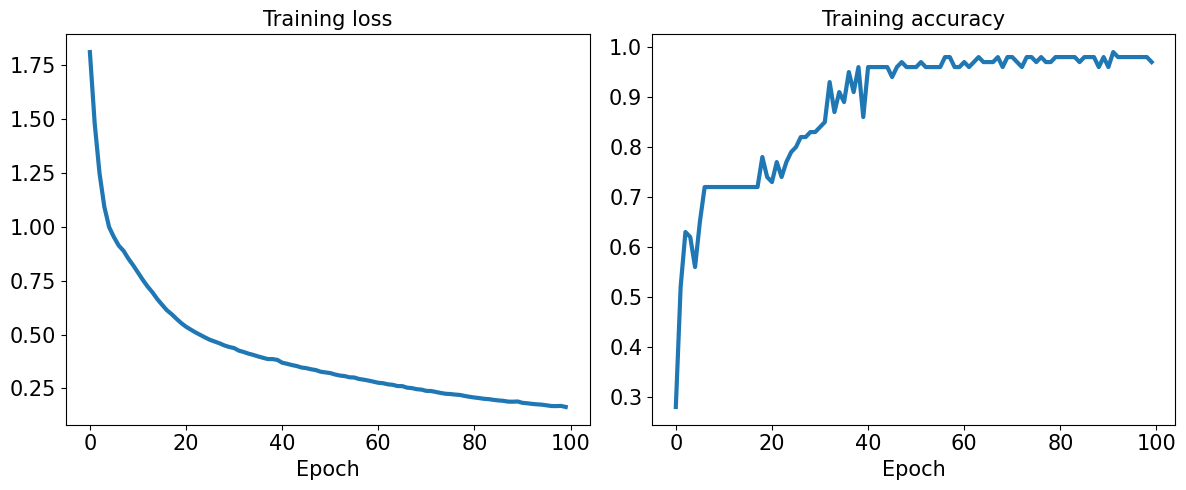

In [77]:
# week6_2.txt
hist = history.history

fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1)
ax.plot(hist['loss'], lw=3)
ax.set_title('Training loss', size=15)
ax.set_xlabel('Epoch', size=15)
ax.tick_params(axis='both', which='major', labelsize=15)

ax = fig.add_subplot(1, 2, 2)
ax.plot(hist['accuracy'], lw=3)
ax.set_title('Training accuracy', size=15)
ax.set_xlabel('Epoch', size=15)
ax.tick_params(axis='both', which='major', labelsize=15)
plt.tight_layout()

plt.show()

In [78]:
results = iris_model.evaluate(ds_test.batch(50), verbose=0)
print('테스트 손실: {:.4f}   테스트 정확도: {:.4f}'.format(*results))

테스트 손실: 0.1658   테스트 정확도: 0.9800
